# Workstream C: neurotransmitters and local circuits (Project 3)

Question: how reliable are transmitter labels, and what does a local circuit look like?

Everything below is read from `data/cache`; there are no network calls. EDA looks at structure and labels, never at model performance.
Datasets: FlyWire FAFB (materialisation 783, annotations v3.2.0, Buhmann) and male CNS v1.0 (Traced, confidence >= 0.5, brain part only).
Provisional region flags come from `eda_shared` v0.1.1 and may change after Project 1's review.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)      # config.py uses relative paths (data/cache); nbconvert starts in notebooks/

In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import eda_utils as U, eda_c as C
from src.report_c import write_report
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
N_SEEDS = int(os.environ.get("EDA_N_SEEDS", 100))      # C6 null graphs; the plan asks for seeds 0-99
WORKERS = int(os.environ.get("EDA_WORKERS", 1))        # raise to use several cores for C6
C6_MAX_MIN = float(os.environ["EDA_C6_MAX_MINUTES"]) if os.environ.get("EDA_C6_MAX_MINUTES") else None   # time budget for C6
R = {"open_points": []}
CAP = "FAFB 783 (annotations v3.2.0, Buhmann) and male CNS v1.0 (Traced, conf >= 0.5, brain part). Provisional flags: eda_shared v0.1.1."
data = {d: U.load(d) for d in C.DS}
R["unspecified"] = {k: int(v) for k, v in data["malecns"][0]["region"].astype(str).value_counts().items() if "unspecified" in k}
for d, (n, e) in data.items():
    print(f"{U.LABEL[d]:8s} neurons {len(n):>9,}   edges {len(e):>11,}   optic {int(n['is_optic'].sum()):>8,}   central {int((~n['is_optic']).sum()):>8,}")

FAFB     neurons   139,255   edges  15,091,983   optic   94,768   central   44,487
MaleCNS  neurons   142,757   edges  21,361,769   optic   98,769   central   43,988


## C1. Transmitter composition

**Why:** checks D4 and gives the evidence D20 asks for. Raw percentages only; no excitatory/inhibitory summary.
Four figures per population: neurons or output synapses, by super_class or by region_group.

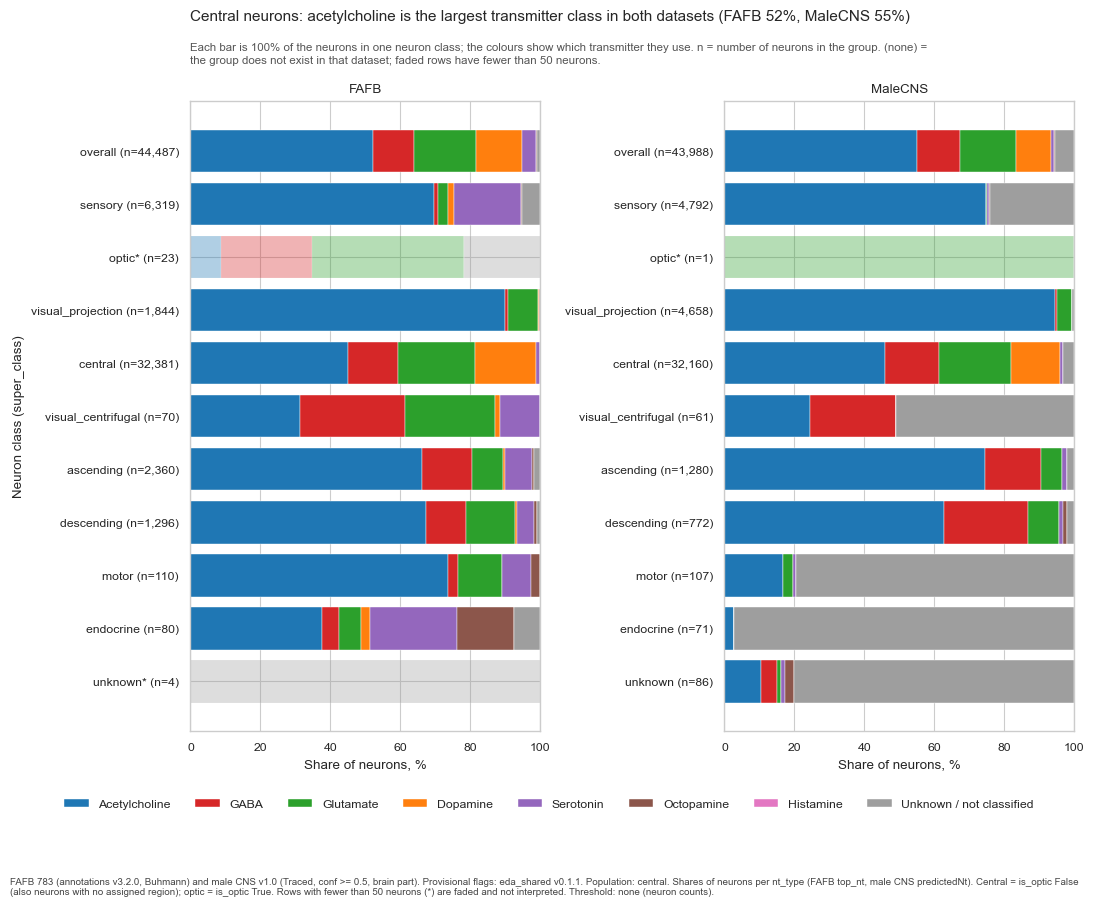

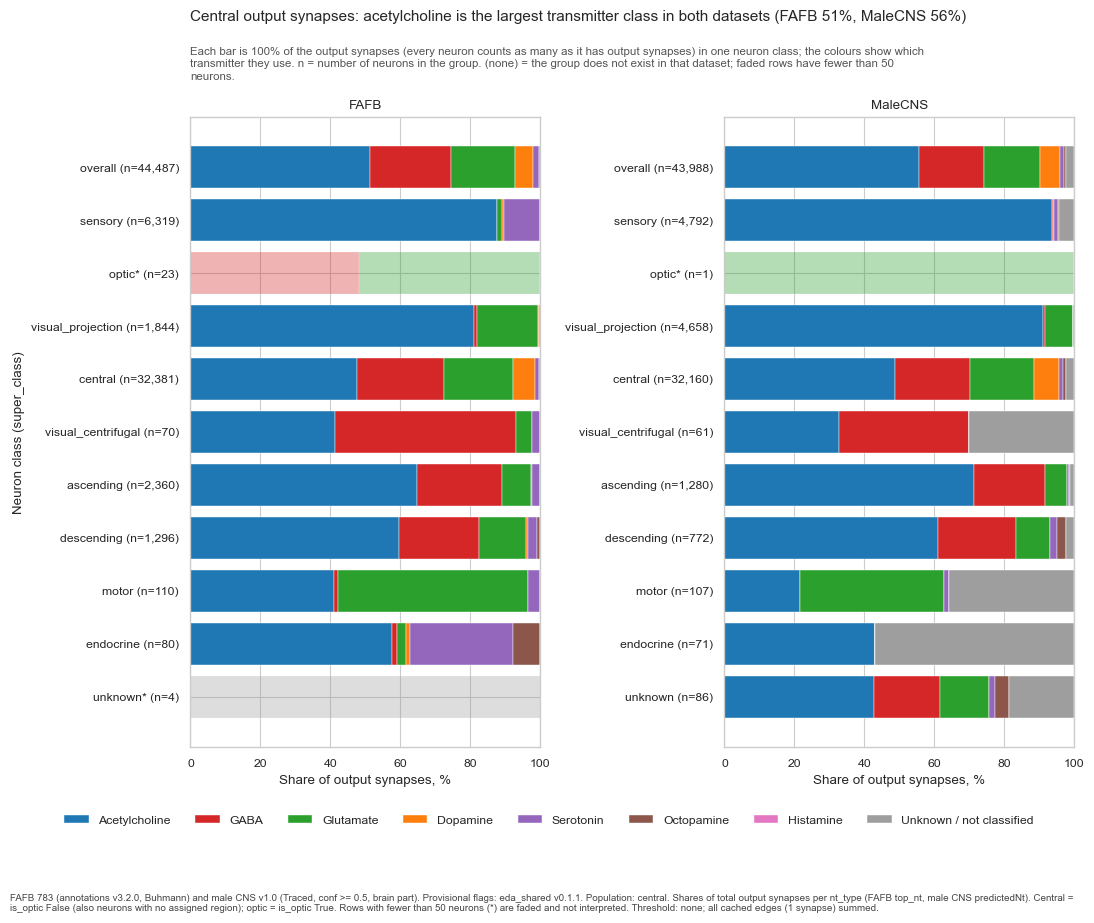

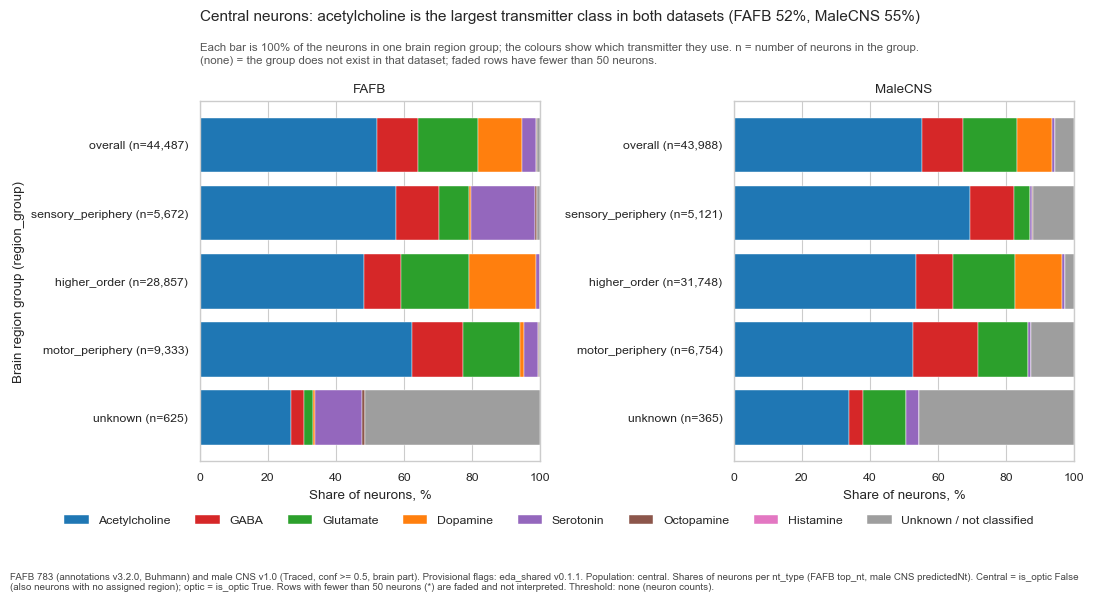

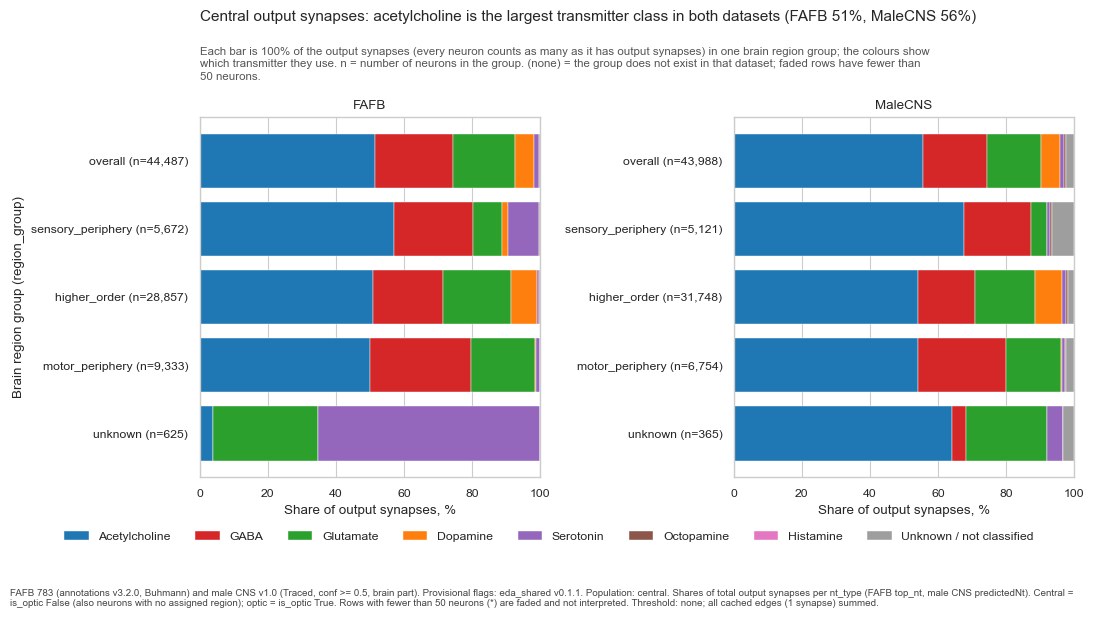

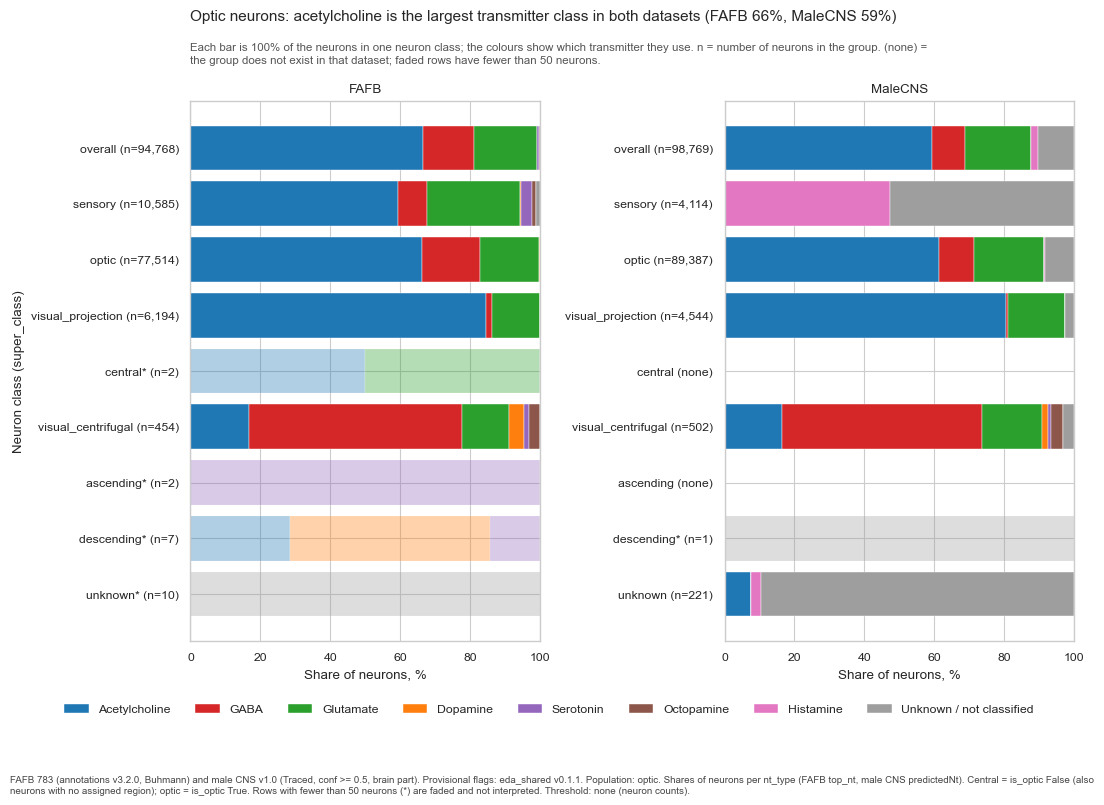

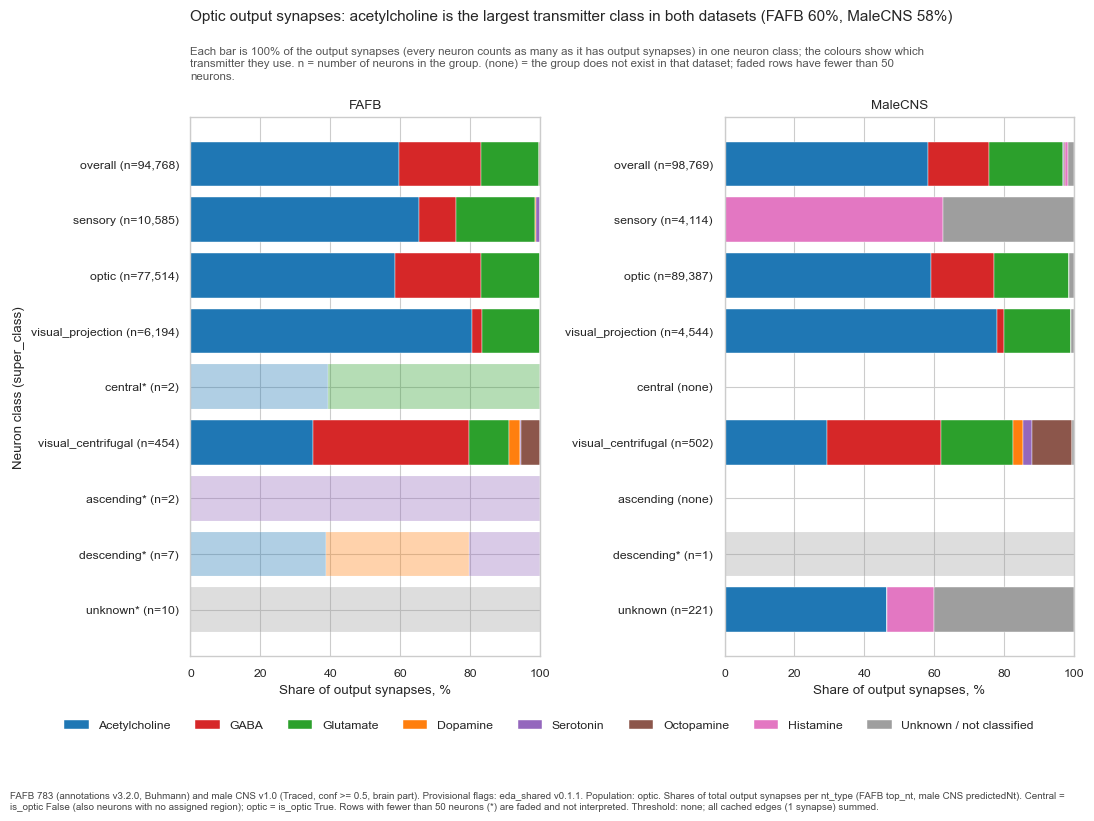

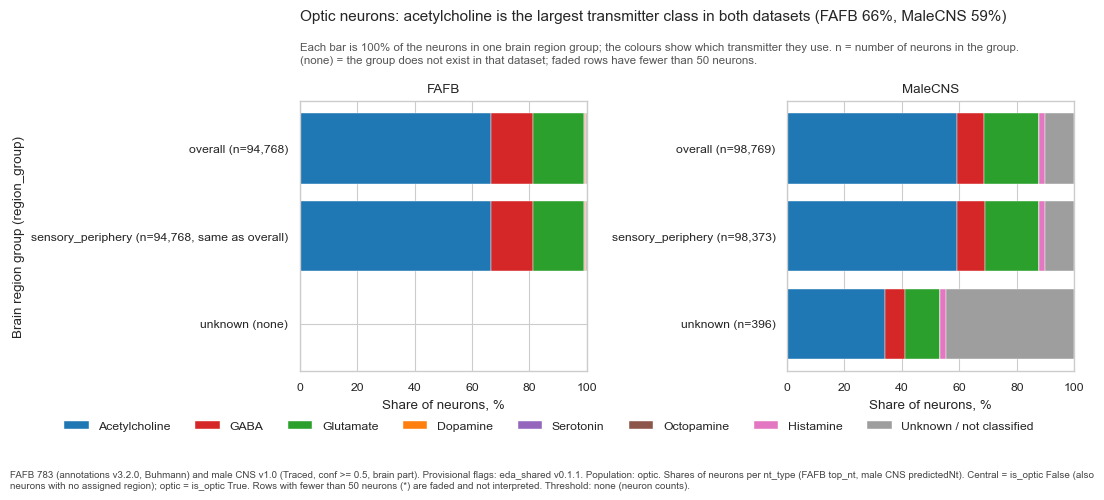

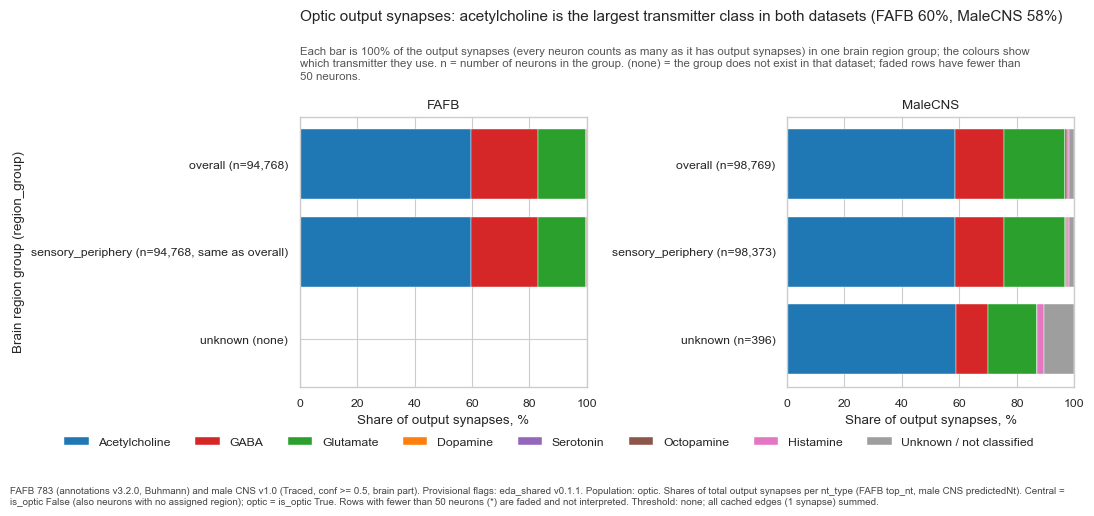

central          optic        
                 fafb malecns   fafb malecns
acetylcholine   0.521   0.552  0.665   0.592
gaba            0.119   0.121  0.147   0.095
glutamate       0.176   0.160  0.180   0.190
dopamine        0.131   0.101  0.001   0.000
serotonin       0.041   0.008  0.005   0.000
octopamine      0.002   0.001  0.001   0.000
histamine       0.000   0.000  0.000   0.020
unknown         0.009   0.056  0.002   0.102

In [3]:
R["C1"] = {}
R["C1_weighted"] = {}
for pop in ("central", "optic"):
    for by in ("super_class", "region_group"):
        for weighted in (False, True):
            fig, tabs = C.c1_figure(data, pop, by, weighted)
            tag = by + ("_weighted" if weighted else "")
            U.save(fig, U.fig_name("C1", "both", pop, extra=tag), C.c1_caption(CAP, pop, weighted))
            if by == "super_class" and not weighted:
                R["C1"][pop] = {d: tabs[d].loc["overall", U.NT_ORDER].astype(float).to_dict() for d in C.DS}
            if by == "super_class" and weighted:
                R["C1_weighted"][pop] = {d: tabs[d].loc["overall", U.NT_ORDER].astype(float).to_dict() for d in C.DS}
            plt.show()
pd.DataFrame({(pop, d): pd.Series(R["C1"][pop][d]) for pop in R["C1"] for d in C.DS}).round(3)

## C2. How confident are the labels

**Why:** checks D4 (confidence kept, no cutoff at fetch). Labels are predictions; `nt_known` is the only measured check, and it exists only for FAFB.
Never apply one cutoff to both datasets.

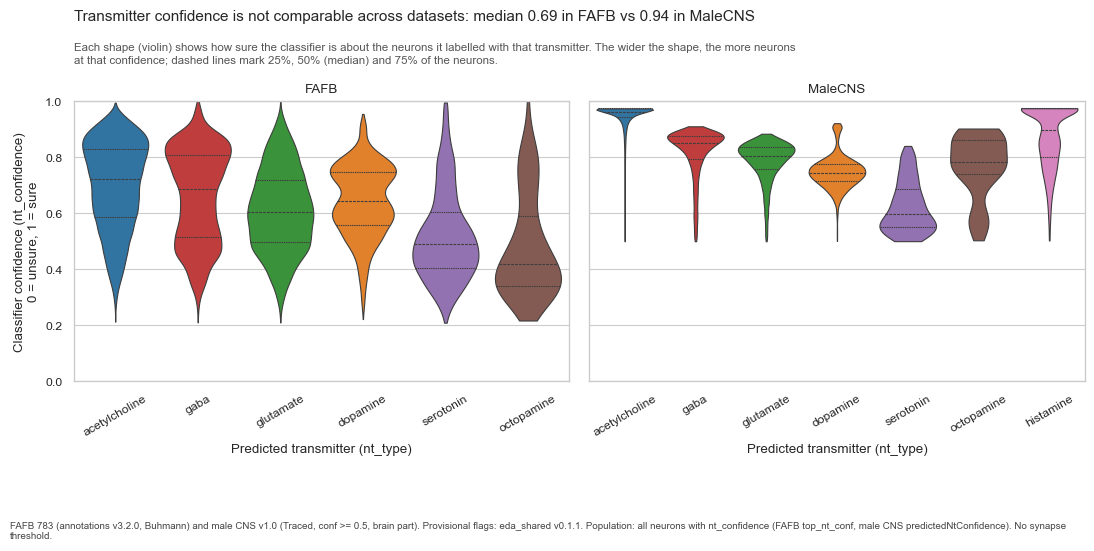

,n,p10,p25,p50
FAFB,138641.0,0.448,0.549,0.686
MaleCNS,130164.0,0.748,0.830,0.938


,count
nt_known filled,87831
single classical transmitter,77182
several transmitters named,4057
only a negative or co-transmitter,6592


,neurons,agree
k,,
acetylcholine,49636,0.873
histamine,9799,0.000
glutamate,9717,0.805
gaba,7501,0.946
dopamine,390,0.962
serotonin,79,0.203
octopamine,60,0.617


nt_type,acetylcholine,dopamine,gaba,glutamate,octopamine,serotonin,unknown
nt_known,,,,,,,
acetylcholine,43317,5201,134,214,4,754,12
dopamine,2,375,1,7,0,5,0
gaba,286,0,7097,114,0,1,3
glutamate,267,6,1603,7819,4,18,0
histamine,5662,30,799,2406,97,406,399
octopamine,1,3,17,2,37,0,0
serotonin,11,42,4,5,1,16,0


In [4]:
fig = C.c2_figure(data)
U.save(fig, U.fig_name("C2", "both", "all"), CAP + " Population: all neurons with nt_confidence (FAFB top_nt_conf, male CNS predictedNtConfidence). No synapse threshold.")
plt.show()
pct = pd.DataFrame({U.LABEL[d]: C.c2_percentiles(data[d][0]) for d in C.DS}).T
display(pct.round(3))
below = {d: float((data[d][0]["nt_confidence"].dropna() < 0.6).mean()) for d in C.DS}
cover, per, cross = C.c2_agreement(data["fafb"][0])
display(cover); display(per.assign(agree=per["agree"].round(3))); display(cross)
tot_n = int(per["neurons"].sum())
R["C2"] = {d: {"p50": float(pct.loc[U.LABEL[d], "p50"]), "below_06": below[d],
               "by_nt": {k: float(v) for k, v in data[d][0].dropna(subset=["nt_confidence"]).groupby("nt_type")["nt_confidence"].median().items()}}
           for d in C.DS}
R["C2"]["agreement"] = float((per["agree"] * per["neurons"]).sum() / tot_n) if tot_n else float("nan")
R["C2"]["agreement_n"] = tot_n
pe = per.drop(index="histamine", errors="ignore")   # the FlyWire classifier has no histamine class, so those neurons can never agree
R["C2"]["agreement_excl_hist"] = float((pe["agree"] * pe["neurons"]).sum() / pe["neurons"].sum())
R["C2"]["agreement_excl_hist_n"] = int(pe["neurons"].sum())
def row_share(known, pred):
    return float(cross.loc[known, pred] / cross.loc[known].sum()) if known in cross.index and pred in cross.columns else float("nan")
R["C2"]["ach_to_da"] = row_share("acetylcholine", "dopamine"); R["C2"]["glu_to_gaba"] = row_share("glutamate", "gaba")

In [5]:
# C2b (supplementary): male CNS predictedNt against consensusNt. Needs the file written by fetch_malecns.
import config
cons_path = U.config.CACHE_DIR / "malecns_nt_consensus_v1.0.parquet"
tab = C.c2b_consensus(data["malecns"][0], cons_path)
if tab is None:
    print("no consensusNt file in the cache: skipped"); R["C2b"] = None
else:
    display(tab)
    m = data["malecns"][0].merge(pd.read_parquet(cons_path), on="neuron_id", how="left")
    cons = m["consensusNt"].astype("string").str.lower().replace({"unclear": "unknown"})
    agree = float((m["nt_type"].astype(str) == cons).mean())
    kc = m[m["cell_type"].astype("string").str.startswith("KC", na=False)]
    kc_top = kc["nt_type"].astype(str).value_counts()
    R["C2b"] = {"agree": agree, "kc_top": kc_top.index[0] if len(kc_top) else "n/a",
                "kc_share": float(kc_top.iloc[0] / len(kc)) if len(kc) else float("nan")}
    R["open_points"].append("which male CNS transmitter label to use (predictedNt has no sensible Kenyon-cell class)" if R["C2b"]["kc_top"] != "acetylcholine" else "male CNS predictedNt vs consensusNt agree for Kenyon cells")
    cen = m[~m["is_optic"]]
    def share(series, k): return float((series == k).mean())
    cons_c = cen["consensusNt"].astype("string").str.lower().replace({"unclear": "unknown"})
    R["C2b"].update({"central_ach_pred": share(cen["nt_type"].astype(str), "acetylcholine"), "central_da_pred": share(cen["nt_type"].astype(str), "dopamine"),
                     "central_ach_cons": share(cons_c, "acetylcholine"), "central_da_cons": share(cons_c, "dopamine")})
    print(R["C2b"])

consensusNt,acetylcholine,dopamine,gaba,glutamate,histamine,octopamine,serotonin,unknown
predictedNt (nt_type),,,,,,,,
acetylcholine,82368,0,45,94,0,0,0,240
dopamine,4058,382,0,0,0,0,0,3
gaba,20,0,14652,4,0,0,0,50
glutamate,22,0,364,25145,0,0,0,258
histamine,0,0,0,33,1964,0,0,0
octopamine,8,0,4,1,0,51,0,20
serotonin,75,0,0,0,1,0,26,276
unknown,4566,10,1418,1512,3941,0,5,1141


{'agree': 0.880607479911935, 'kc_top': 'dopamine', 'kc_share': 0.9985236220472441, 'central_ach_pred': 0.5515367827589343, 'central_da_pred': 0.10082295171410385, 'central_ach_cons': 0.6779977246871445, 'central_da_cons': 0.008737201365187713}


## C3. Do hemilineages share a transmitter

**Why:** checks D1 (Ito-Lee hemilineage kept): how informative the column is where it is filled.
FAFB neurons with a hemilineage and a fast transmitter (acetylcholine, GABA, glutamate); hemilineages with at least 20 such neurons.

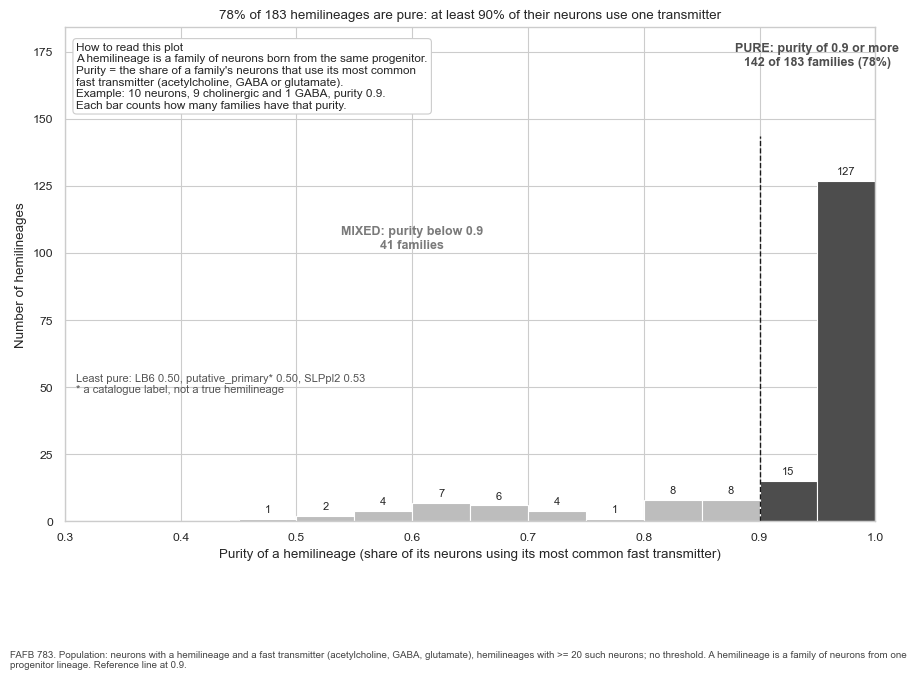

,neurons,dominant,share
hemilineage,,,
LB6,107,glutamate,0.495
putative_primary,3607,acetylcholine,0.503
SLPpl2,86,acetylcholine,0.535
VPNp&v1_posterior,391,gaba,0.552
primary,36,gaba,0.556
LB3__prim,28,glutamate,0.571
LHl3,28,gaba,0.571
DL1_ventral,286,acetylcholine,0.601
LALv1_ventral,194,acetylcholine,0.603


In [6]:
hl = C.c3_hemilineages(data["fafb"][0])
fig = C.c3_figure(hl)
U.save(fig, U.fig_name("C3", "fafb", "all"), "FAFB 783. Population: neurons with a hemilineage and a fast transmitter (acetylcholine, GABA, glutamate), hemilineages with >= 20 such neurons; no threshold. A hemilineage is a family of neurons from one progenitor lineage. Reference line at 0.9.")
plt.show()
low = hl[hl["share"] < 0.8]
display(low.round(3))
R["C3"] = {"n": len(hl), "share_ge_09": float((hl["share"] >= 0.9).mean()), "n_lt_08": len(low), "lt_08": list(low.index)}

## C4. What the glutamate choice changes

**Why:** D20 asks which results change under the opposite glutamate choice; this shows where.
Rule 1: ACh = E; GABA and glutamate = I. Rule 2: ACh and glutamate = E; GABA = I. Modulatory and unknown are left out of both.

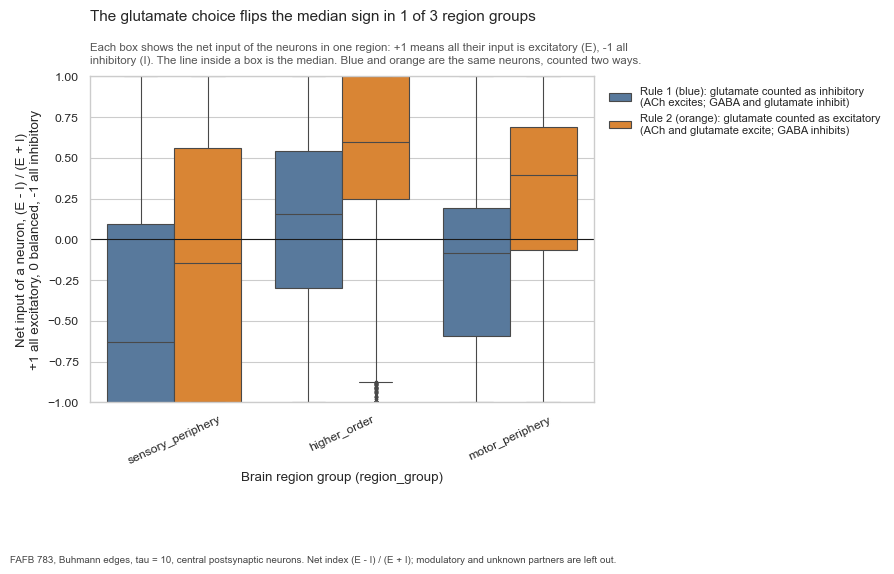

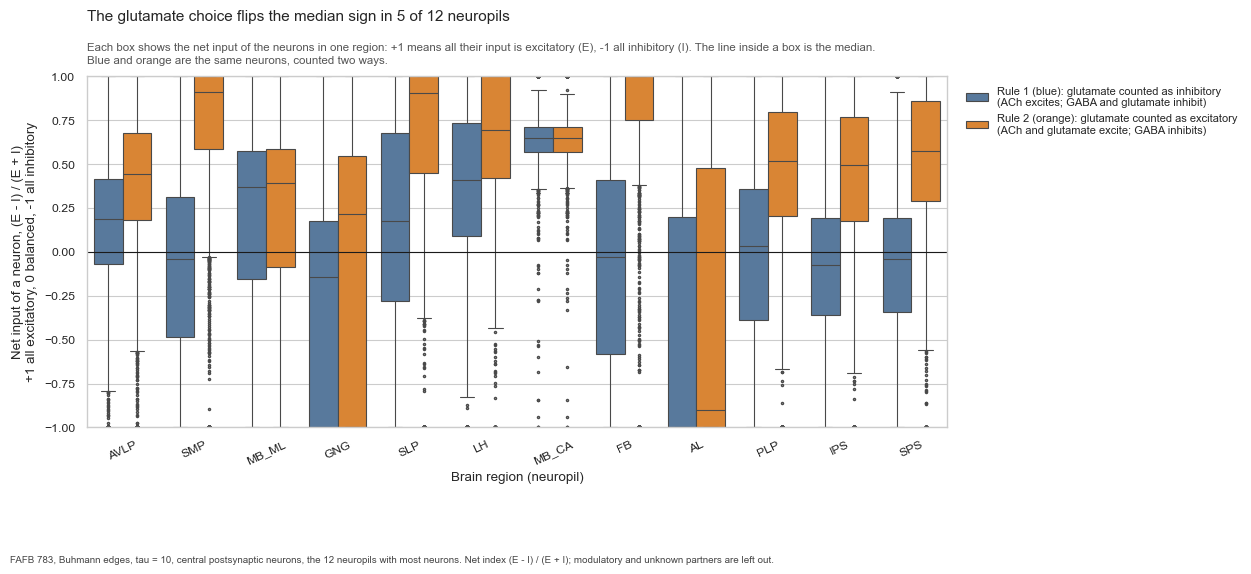

rule,"Rule 1: ACh = E; GABA, Glu = I","Rule 2: ACh, Glu = E; GABA = I",changes_sign,n
region_group,,,,
higher_order,0.156,0.594,False,25976
motor_periphery,-0.086,0.395,True,6079
sensory_periphery,-0.630,-0.146,False,3159


rule,"Rule 1: ACh = E; GABA, Glu = I","Rule 2: ACh, Glu = E; GABA = I",changes_sign,n
neuropil,,,,
AL,-1.000,-0.902,False,1531
AVLP,0.185,0.443,False,3603
FB,-0.031,1.000,True,1639
GNG,-0.145,0.213,True,3028
IPS,-0.074,0.496,True,1301
LH,0.408,0.693,False,2177
MB_CA,0.650,0.650,False,1759
MB_ML,0.367,0.392,False,3107
PLP,0.031,0.515,False,1527


In [7]:
net = C.c4_net_index(*data["fafb"], tau=10)
fig = C.c4_figure(net, "region_group")
U.save(fig, U.fig_name("C4", "fafb", "central", tau=10, extra="region_group"), "FAFB 783, Buhmann edges, tau = 10, central postsynaptic neurons. Net index (E - I) / (E + I); modulatory and unknown partners are left out.")
plt.show()
fig = C.c4_figure(net, "neuropil", top=12)
U.save(fig, U.fig_name("C4", "fafb", "central", tau=10, extra="neuropil12"), "FAFB 783, Buhmann edges, tau = 10, central postsynaptic neurons, the 12 neuropils with most neurons. Net index (E - I) / (E + I); modulatory and unknown partners are left out.")
plt.show()
sc_g = C.c4_sign_changes(net, "region_group")
top12 = net.drop_duplicates("neuron_id")["neuropil"].value_counts().head(12).index
sc_n = C.c4_sign_changes(net[net["neuropil"].isin(top12)], "neuropil")
display(sc_g.round(3)); display(sc_n.round(3))
R["C4"] = {"n_groups": len(sc_g), "n_groups_flip": int(sc_g["changes_sign"].sum()), "groups_flip": list(sc_g.index[sc_g["changes_sign"]]),
           "n_neuropils": len(sc_n), "n_neuropils_flip": int(sc_n["changes_sign"].sum()), "neuropils_flip": list(sc_n.index[sc_n["changes_sign"]])}
r1, r2 = list(C.RULES)
shift = (sc_n[r2] - sc_n[r1]).abs()
R["C4"].update({"n_shift": int((shift >= 0.25).sum()), "shift_lo": float(shift[shift >= 0.25].min()), "shift_hi": float(shift.max())})

## C5. The mushroom body subgraph

**Why:** Project 3's first measurement: is the subgraph large and dense enough to model?
Selection = neurons whose region is a mushroom body neuropil. The list used is printed below. The week 2 subgraph was selected by cell type, so a second selection is shown for continuity; the two are not the same set.

mushroom body neuropils used: ['MB_CA', 'MB_PED', 'MB_VL', 'MB_ML']


,dataset,selection,tau,neurons,edges,density,isolated,median_in,median_out,median_in_connected,median_out_connected
0,FAFB,region,1,5293,473647,0.0169,3,70.0,81.0,70.0,81.0
1,FAFB,region,5,5293,42326,0.0015,38,2.0,6.0,2.0,6.0
2,FAFB,region,10,5293,20645,0.0007,117,1.0,3.0,1.0,3.0
3,FAFB,cell_type,1,5612,531303,0.0169,0,72.0,88.0,72.0,88.0
4,FAFB,cell_type,5,5612,44745,0.0014,32,1.0,6.0,1.0,6.0
5,FAFB,cell_type,10,5612,20219,0.0006,138,1.0,3.0,1.0,3.0
6,MaleCNS,region,1,4435,981780,0.0499,0,184.0,193.0,184.0,193.0
7,MaleCNS,region,5,4435,87431,0.0044,6,9.0,15.0,9.0,15.0
8,MaleCNS,region,10,4435,30314,0.0015,48,2.0,6.0,2.0,6.0
9,MaleCNS,cell_type,1,4510,1027148,0.0505,0,185.0,201.0,185.0,201.0


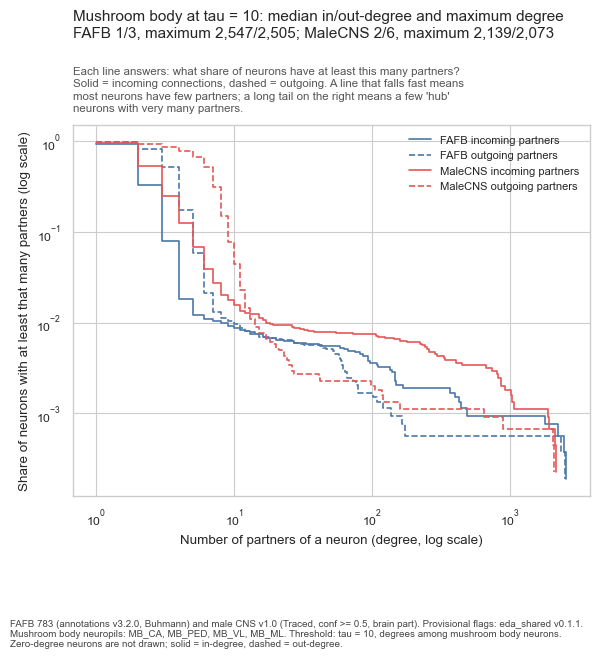

In [8]:
print("mushroom body neuropils used:", C.mb_neuropils())
tab5 = C.c5_table(data)
display(tab5.round(4))
fig = C.c5_ccdf_figure(data, tau=10)
U.save(fig, U.fig_name("C5", "both", "all", tau=10, extra="degree_ccdf"), CAP + " Mushroom body neuropils: " + ", ".join(C.mb_neuropils()) + ". Threshold: tau = 10, degrees among mushroom body neurons. Zero-degree neurons are not drawn; solid = in-degree, dashed = out-degree.")
plt.show()
def pick(d, tau, sel="region"):
    r = tab5[(tab5["dataset"] == U.LABEL[d]) & (tab5["tau"] == tau) & (tab5["selection"] == sel)].iloc[0]
    return r
R["C5"] = {d: {"neurons": int(pick(d, 10).neurons), "edges": int(pick(d, 10).edges), "density": float(pick(d, 10).density),
               "isolated": int(pick(d, 10).isolated), "isolated_5": int(pick(d, 5).isolated),
               "edges_1": int(pick(d, 1).edges), "edges_5": int(pick(d, 5).edges), "edges_5_isolated": int(pick(d, 5).isolated),
               "median_in": float(pick(d, 10).median_in), "median_out": float(pick(d, 10).median_out),
               "ct_isolated_10": int(pick(d, 10, "cell_type").isolated), "ct_isolated_5": int(pick(d, 5, "cell_type").isolated)} for d in C.DS}

## C6. Non-random structure in the subgraph

**Why:** checks the shared randomiser on real data before every project's null model relies on it, and shows structure beyond degree.
Null: `randomise_edges` with seeds 0 to N_SEEDS - 1 (the plan asks for 0 to 99). z = (observed - null mean) / null standard deviation (sample SD). If the randomiser warns that it cannot mix a dense graph, report the warning with the result.

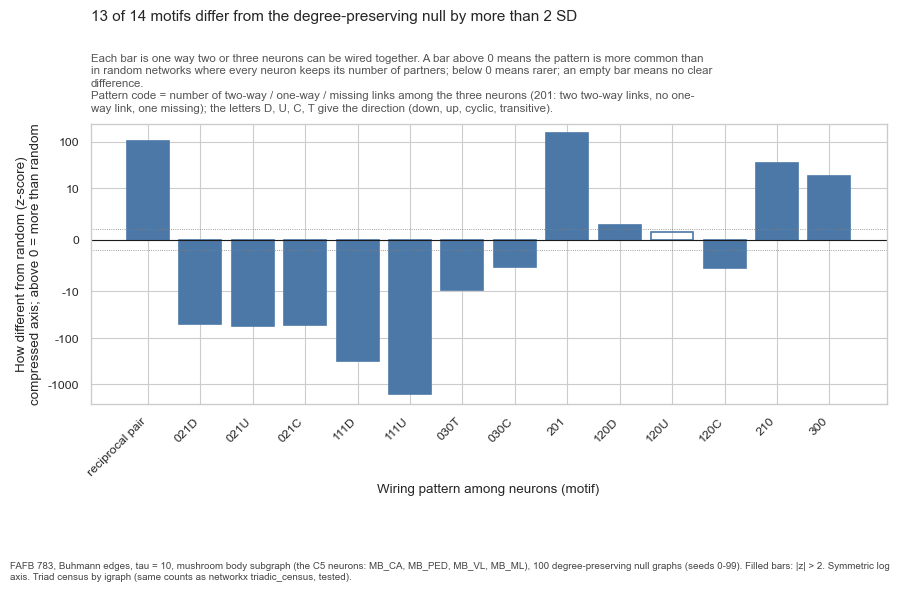

,observed,null_mean,null_sd,z
reciprocal pair,4950,2420.09,24.505,103.240
021D,94137,1640625.03,30623.983,-50.499
021U,4542066,6306887.23,32155.781,-54.883
021C,60465,3370353.36,62192.795,-53.220
111D,556398,3201168.15,8474.394,-312.090
111U,94243,2956226.91,1746.032,-1639.136
030T,1106,8459.78,762.477,-9.645
030C,27,3242.06,608.970,-5.280
201,5810629,1411015.48,29391.127,149.692
120D,3886,2463.10,488.841,2.911


5936

In [9]:
z = C.c6_motifs(*data["fafb"], tau=10, n_seeds=N_SEEDS, workers=WORKERS, max_minutes=C6_MAX_MIN,
                progress_path=U.ROOT / "reports" / "c6_progress.txt")      # watch this file from a second window
N_USED = z.attrs["n_seeds"]
fig = C.c6_figure(z, tau=10)
U.save(fig, U.fig_name("C6", "fafb", "all", tau=10), f"FAFB 783, Buhmann edges, tau = 10, mushroom body subgraph (the C5 neurons: {', '.join(C.mb_neuropils())}), {N_USED} degree-preserving null graphs (seeds 0-{N_USED-1}). Filled bars: |z| > 2. Symmetric log axis. Triad census by igraph (same counts as networkx triadic_census, tested).")
plt.show()
display(z.round(3))
R["C6"] = {"n_seeds": N_USED, "z_recip": float(z.loc["reciprocal pair", "z"]), "sig": [m for m in z.index if abs(z.loc[m, "z"]) > 2],
           "over": [m for m in z.index if z.loc[m, "z"] > 2], "under": [m for m in z.index if z.loc[m, "z"] < -2],
           "obs_recip": int(z.loc["reciprocal pair", "observed"]), "null_recip": float(z.loc["reciprocal pair", "null_mean"]),
           "z_abs_max": float(z["z"].abs().max())}
import json
(U.ROOT / "reports").mkdir(exist_ok=True)
(U.ROOT / "reports" / "eda_C_numbers.json").write_text(json.dumps(R, indent=1, default=str), encoding="utf-8")

## One-page summary

Writes a draft of `reports/eda_C.md` from the numbers above. The numbers are exact; edit the sentences in your own words and write the surprise line yourself.

In [10]:
print(write_report(R, U.ROOT / "reports" / "eda_C.md"))

# Workstream C: neurotransmitters and local circuits

FlyWire FAFB 783 and male CNS v1.0 (brain part). EDA looks at structure and labels only. Population and threshold are stated per line.

- **C1 (central, neurons)**: acetylcholine 52% in FAFB and 55% in MaleCNS; GABA 12% / 12%, glutamate 18% / 16%, unknown 1% / 6%. Acetylcholine is the largest class in both datasets, as expected.
- **C2 (all neurons, confidence)**: median confidence 0.69 (FAFB) vs 0.94 (MaleCNS); a 0.6 cutoff would remove 34% vs 2%, so one cutoff cannot be applied to both. Where nt_known names one transmitter, nt_type agrees for 87% of FAFB neurons (76% if the histamine neurons, which the classifier cannot predict, are counted). 10% of known cholinergic neurons are predicted dopamine and 16% of known glutamate neurons are predicted GABA.
- **C2b (male CNS, supplementary)**: predictedNt and consensusNt agree for 88% of brain neurons; among Kenyon-type neurons predictedNt says dopamine for 100%. This is the check behin